# Input--response forecasting with AR and ARX

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/sequential-models/02-silverbox-arx.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

The [Silverbox benchmark](https://www.nonlinearbenchmark.org/benchmarks/silverbox) records the response of an electronic system designed to behave like a Duffing oscillator. It provides one deliberately applied input, `V1`, and one measured response, `V2`. A useful mechanical analogy is a force-like excitation $u_t$ and a displacement-like response $y_t$.

We will forecast the response first from its past values alone, then with the known applied input. Both models use the same chronological training/held-out experiment split and the same recursive multi-step test.


## What you will do

1. Load one real input--response system-identification benchmark.
2. Preserve its chronological training/test experiment split.
3. Fit an AR(20) model using only past response values.
4. Add the known forcing signal to create an ARX(20) model.
5. Compare the two models using the same recursive multi-step held-out forecast.


## 1. Load the measured input--response experiments

The `nonlinear-benchmarks` package downloads the official Silverbox record to the notebook runtime. Nothing is fitted to the held-out experiment.


In [1]:
# This package downloads the official Silverbox benchmark when it is first used.
try:
    from nonlinear_benchmarks import Silverbox
except ModuleNotFoundError:
    %pip install -q nonlinear-benchmarks
    from nonlinear_benchmarks import Silverbox

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_SEED = 7
np.random.seed(RANDOM_SEED)


In [2]:
# Store the official download in the notebook's local working directory.
# In Colab, this directory is temporary and disappears when the runtime ends.
benchmark_directory = Path("silverbox-data")
benchmark_directory.mkdir(exist_ok=True)
training_record, test_records = Silverbox(dir_placement=benchmark_directory)
test_record = test_records[0]  # Select the held-out record.

u_train = np.asarray(training_record.u, dtype=float).reshape(-1)
y_train = np.asarray(training_record.y, dtype=float).reshape(-1)
u_test = np.asarray(test_record.u, dtype=float).reshape(-1)
y_test = np.asarray(test_record.y, dtype=float).reshape(-1)
sampling_time = float(training_record.sampling_time)

print(f"Training samples: {len(y_train):,}")
print(f"Held-out samples: {len(y_test):,}")
print(f"Sampling interval: {sampling_time * 1_000:.4f} ms")


dataset not found downloading from https://drive.google.com/file/d/17iS-6oBUUgrmiAcrZoG9S5sOaljZnDSy/view 
 in silverbox-data/Silverbox/SilverboxFiles.zip


extracting file...
save_loc='silverbox-data/Silverbox/SilverboxFiles.zip'
Training samples: 65,062
Held-out samples: 21,688
Sampling interval: 1.6384 ms


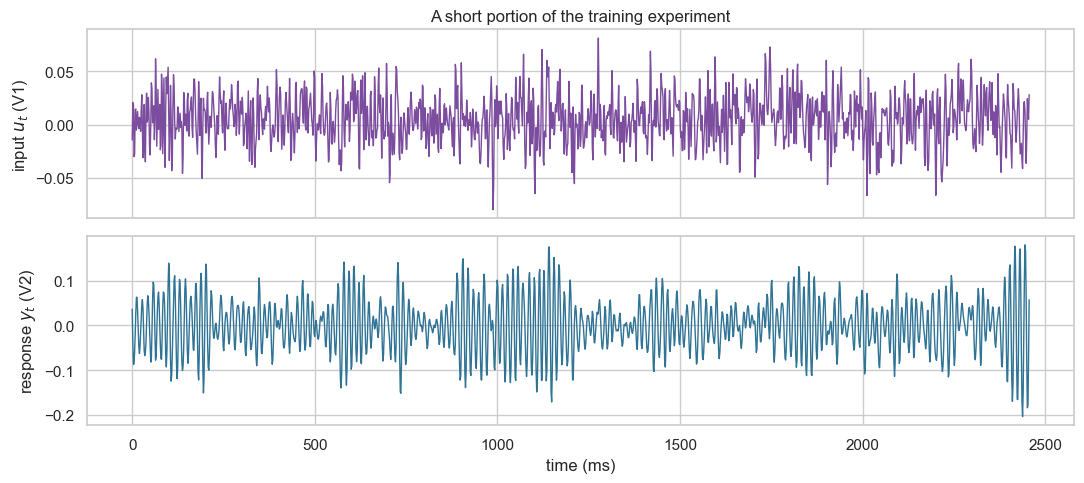

In [3]:
display_samples = 1_500
time_ms = np.arange(display_samples) * sampling_time * 1_000

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(time_ms, u_train[:display_samples], color="#7c4d9e", linewidth=1)
axes[0].set(ylabel="input $u_t$ (V1)", title="A short portion of the training experiment")
axes[1].plot(time_ms, y_train[:display_samples], color="#2f7395", linewidth=1)
axes[1].set(xlabel="time (ms)", ylabel="response $y_t$ (V2)")
plt.tight_layout()
plt.show()

## 2. Set up one forecasting protocol

An **autoregressive (AR)** model forecasts a response from its own past values. An **autoregressive model with exogenous input (ARX)** extends that idea by adding one or more external signals that are available at prediction time. Such an input might be a commanded actuator signal, an ambient measurement, or a known operating schedule; it is *exogenous* because it is supplied from outside the response's own history.

Here, `V1` is the exogenous input and `V2` is the response. We first forecast `V2` purely from its own past values, then add the known applied input `V1`.

There are two useful forecasting protocols:

- **One-step-ahead forecasting (observed lags):** use the actual preceding `V2` measurements at every time step.
- **Recursive multi-step forecasting (predicted lags):** after an initial window, reuse each prediction as a lagged `V2` input for later predictions.

We use recursive multi-step forecasting throughout this notebook. Every model uses the last $p$ measured training responses to initialize its lag history. It predicts from the first held-out sample; held-out `V2` responses are **not** fed back to the model.

The applied input $u_t$ remains known throughout the held-out experiment. That is natural in system identification: it is an externally imposed forcing signal, not an unknown future response measurement.

For this example, the two linear models are

$$
\begin{aligned}
\text{AR}(p):\quad \widehat{y}_t &= \beta_0 + \sum_{j=1}^{p}\beta_j y_{t-j},\\
\text{ARX}(p):\quad \widehat{y}_t &= \beta_0 + \sum_{j=1}^{p}\beta_j y_{t-j} + \sum_{j=0}^{p}\gamma_j u_{t-j}.
\end{aligned}
$$


In [4]:
ORDER = 20


def make_linear_design(
    *,
    input_signal: np.ndarray,
    output_signal: np.ndarray,
    order: int,
    include_input: bool,
) -> tuple[np.ndarray, np.ndarray]:
    """Build one-step input rows for an AR or ARX model."""
    rows: list[np.ndarray] = []
    targets: list[float] = []
    for index in range(order, len(output_signal)):
        response_lags = output_signal[index - order : index][::-1]
        if include_input:
            input_lags = input_signal[index - order : index + 1][::-1]
            rows.append(np.concatenate((response_lags, input_lags)))
        else:
            rows.append(response_lags)
        targets.append(output_signal[index])
    return np.asarray(rows), np.asarray(targets)


def fit_linear_forecaster(
    *,
    input_signal: np.ndarray,
    output_signal: np.ndarray,
    order: int,
    include_input: bool,
) -> tuple[StandardScaler, LinearRegression]:
    """Fit a linear AR or ARX forecaster using training data only."""
    features, targets = make_linear_design(
        input_signal=input_signal,
        output_signal=output_signal,
        order=order,
        include_input=include_input,
    )
    scaler = StandardScaler().fit(features)
    model = LinearRegression().fit(scaler.transform(features), targets)
    return scaler, model


def recursive_linear_forecast(
    *,
    input_signal: np.ndarray,
    observed_output: np.ndarray,
    order: int,
    include_input: bool,
    scaler: StandardScaler,
    model: LinearRegression,
) -> np.ndarray:
    """Make a recursive multi-step forecast after an initial response window."""
    history = list(observed_output[:order])
    predictions = np.full(len(observed_output), np.nan)
    for index in range(order, len(observed_output)):
        response_lags = np.asarray(history[-order:][::-1])
        if include_input:
            input_lags = input_signal[index - order : index + 1][::-1]
            feature_row = np.concatenate((response_lags, input_lags))
        else:
            feature_row = response_lags
        prediction = model.predict(scaler.transform(feature_row.reshape(1, -1)))[0]
        history.append(float(prediction))
        predictions[index] = prediction
    return predictions


def rmse(*, actual: np.ndarray, predicted: np.ndarray, warmup: int) -> float:
    """Calculate root-mean-square error after the initialization window."""
    return float(np.sqrt(np.mean((actual[warmup:] - predicted[warmup:]) ** 2)))

# Only the final ORDER training observations initialize the forecast.
# Placeholder values make it explicit that held-out responses are not inputs.
forecast_input = np.concatenate((u_train[-ORDER:], u_test))
forecast_history = np.concatenate((y_train[-ORDER:], np.full(len(y_test), np.nan)))


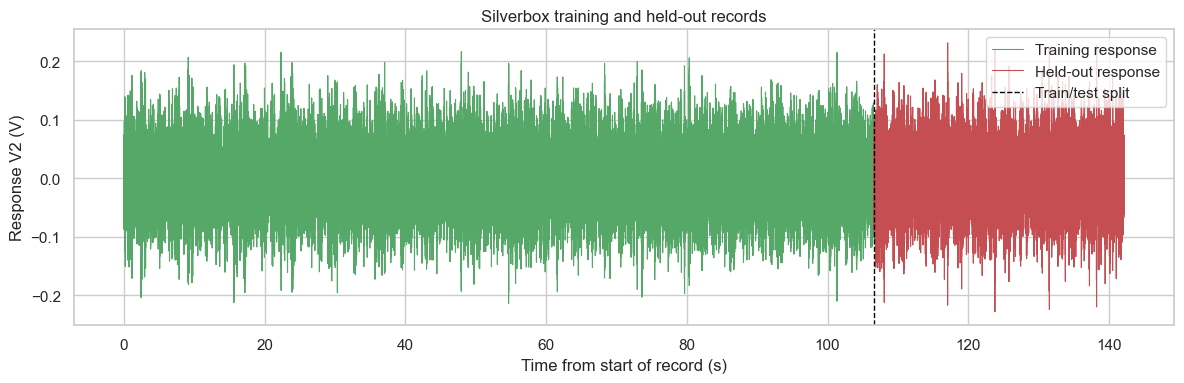

In [5]:
# The loader divides one contiguous record chronologically.
train_time = np.arange(len(y_train)) * sampling_time
test_time = np.arange(len(y_train), len(y_train) + len(y_test)) * sampling_time

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(train_time, y_train, color="#55a868", linewidth=0.8, label="Training response")
ax.plot(test_time, y_test, color="#c44e52", linewidth=0.8, label="Held-out response")
ax.axvline(test_time[0], color="black", linestyle="--", linewidth=1, label="Train/test split")
ax.set(xlabel="Time from start of record (s)", ylabel="Response V2 (V)", title="Silverbox training and held-out records")
ax.legend(frameon=True, loc="upper right")
plt.tight_layout()
plt.show()


### How much of the held-out record do we evaluate?

The benchmark loader splits one continuous record chronologically: the first **65,062 samples** are training data and the next **21,688 samples** are held out. The sampling interval is **1.6384 ms**, so the held-out portion spans about **35.5 seconds**. Both plots use time from the beginning of the complete record.

- The last $p$ training responses initialize the models' lag history. They are not scored; the forecast and evaluation begin at the first held-out sample.
- The models then make a recursive forecast for the rest of the held-out record. The reported RMSE uses **all held-out samples**, not just those shown in a plot.
- To make individual predictions easier to see, the plots in section 4 show two **120-sample windows** within the held-out portion.


## 3. Start with a response-only AR(20) model

The AR model has 20 lagged `V2` values but no access to `V1`. During the recursive multi-step held-out forecast, it must infer future responses solely from its own earlier response forecasts.

In [6]:
ar_scaler, ar_model = fit_linear_forecaster(
    input_signal=u_train,
    output_signal=y_train,
    order=ORDER,
    include_input=False,
)
ar_prediction = recursive_linear_forecast(
    input_signal=forecast_input,
    observed_output=forecast_history,
    order=ORDER,
    include_input=False,
    scaler=ar_scaler,
    model=ar_model,
)[ORDER:]
ar_rmse = rmse(actual=y_test, predicted=ar_prediction, warmup=0)
print(f"AR({ORDER}) recursive multi-step held-out RMSE: {ar_rmse:.5f}")

AR(20) recursive multi-step held-out RMSE: 0.05427


## 4. Add the causal forcing signal: ARX(20)

In this Silverbox system, `V1` is the ARX model's exogenous input. The model receives the same response history plus the current and 20 previous `V1` values. Because `V1` is deliberately imposed on the physical system, it is reasonable to treat it as known at prediction time. This is different from leaking later `V2` labels into the model.

ARX(20) recursive multi-step held-out RMSE: 0.00694


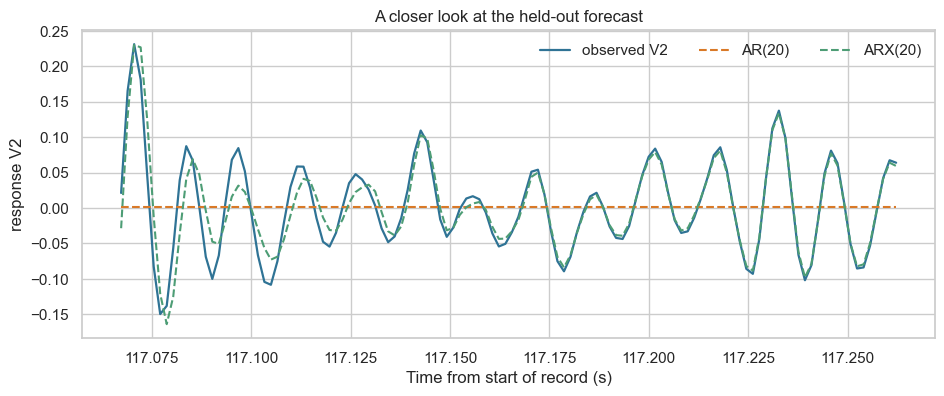

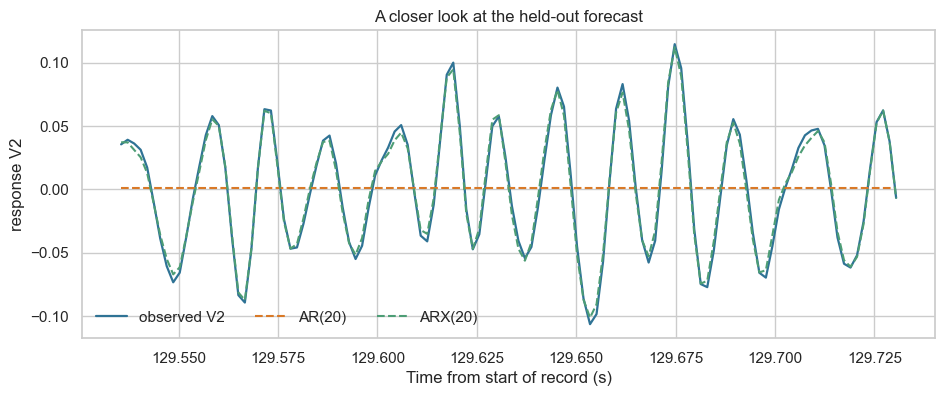

In [7]:
arx_scaler, arx_model = fit_linear_forecaster(
    input_signal=u_train,
    output_signal=y_train,
    order=ORDER,
    include_input=True,
)
arx_prediction = recursive_linear_forecast(
    input_signal=forecast_input,
    observed_output=forecast_history,
    order=ORDER,
    include_input=True,
    scaler=arx_scaler,
    model=arx_model,
)[ORDER:]
arx_rmse = rmse(actual=y_test, predicted=arx_prediction, warmup=0)
print(f"ARX({ORDER}) recursive multi-step held-out RMSE: {arx_rmse:.5f}")

# Inspect two short windows within the held-out portion.
zoom_window_length = 120
for zoom_window_start in (6_390, 14_000):
    zoom_window = slice(zoom_window_start, zoom_window_start + zoom_window_length)
    zoom_time = (len(y_train) + np.arange(zoom_window_start, zoom_window_start + zoom_window_length)) * sampling_time

    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(zoom_time, y_test[zoom_window], color="#2f7395", linewidth=1.6, label="observed V2")
    ax.plot(zoom_time, ar_prediction[zoom_window], color="#d97927", linestyle="--", label="AR(20)")
    ax.plot(zoom_time, arx_prediction[zoom_window], color="#4d9d75", linestyle="--", label="ARX(20)")
    ax.set(
        xlabel="Time from start of record (s)",
        ylabel="response V2",
        title="A closer look at the held-out forecast",
    )
    ax.legend(frameon=False, ncol=3)
    plt.show()

The recursive AR(20) forecast is nearly flat in these windows: without access to `V1`, it cannot respond directly to changes in the applied input. ARX(20) uses the known input and follows the observed response more closely here.


## 5. Takeaway

- AR uses only the response's own previous values.
- ARX adds a known external input, which is appropriate here because `V1` is deliberately imposed on the physical system.
- Both models must recursively reuse their own predicted responses after initialization, so the held-out forecast is a genuine multi-step test.

The next notebook uses the same data and protocol to replace the fixed linear lag representation with a learned nonlinear recurrent state.


<p style="margin-top: 1.5rem;"><a href="index.html">← Return to Sequential models</a></p>